In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

import sys
sys.path.append('../src')

In [2]:
import dendrotweaks as dd

from dendrotweaks.morphology.io import SWCReader
from dendrotweaks.morphology.io import create_point_tree
from dendrotweaks.morphology.io import create_section_tree
from dendrotweaks.morphology.io import validate_tree
from dendrotweaks.morphology.io import create_domains

In [3]:
from etmd.barcodes import elder_rule, sort_bars

In [4]:
PATH_TO_SWC = Path('../data/simple-cell.swc')
PATH_TO_SWC = Path('../data/Park_2019_main_standard.swc')

In [5]:
reader = SWCReader()

In [6]:
df = reader.read_file(PATH_TO_SWC)

In [7]:
point_tree = create_point_tree(df)
sec_tree = create_section_tree(point_tree)

Extended 44 nodes.
Sorted PointTree(root=Point(idx=0), num_nodes=2258).


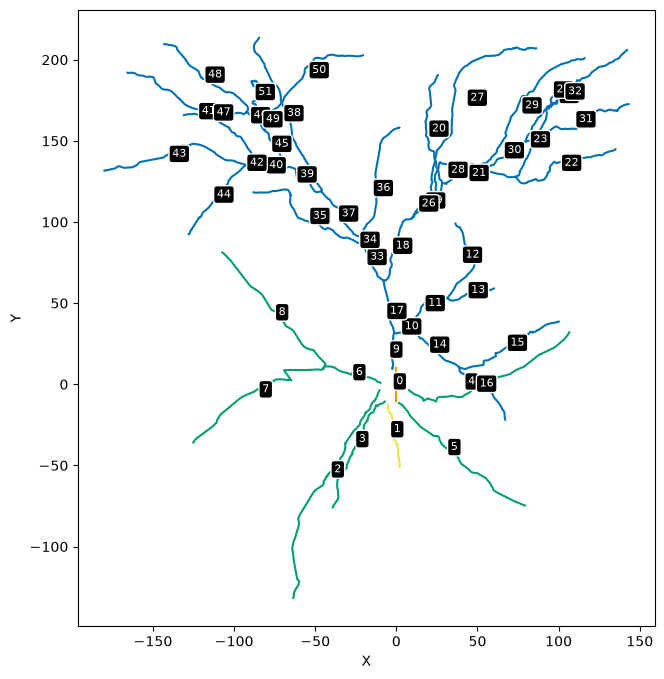

In [8]:
fig, ax = plt.subplots(figsize=(8, 8))
sec_tree.plot(
    ax=ax, 
    show_domains=True, 
    show_points=False, 
    show_lines=True,
    annotate=True
)

In [9]:
sec_tree.topology()

parent |   idx
---------------
    -1 |   •0
     0 |   ├─•1
     0 |   ├─•2
     0 |   ├─•3
     0 |   ├─•4
     0 |   ├─•5
     0 |   ├─•6
     6 |   │ ├─•7
     6 |   │ └─•8
     0 |   └─•9
     9 |     ├─•10
    10 |     │ ├─•11
    11 |     │ │ ├─•12
    11 |     │ │ └─•13
    10 |     │ └─•14
    14 |     │   ├─•15
    14 |     │   └─•16
     9 |     └─•17
    17 |       ├─•18
    18 |       │ ├─•19
    19 |       │ │ ├─•20
    19 |       │ │ └─•21
    21 |       │ │   ├─•22
    21 |       │ │   └─•23
    23 |       │ │     ├─•24
    23 |       │ │     └─•25
    18 |       │ └─•26
    26 |       │   ├─•27
    26 |       │   └─•28
    28 |       │     ├─•29
    28 |       │     └─•30
    30 |       │       ├─•31
    30 |       │       └─•32
    17 |       └─•33
    33 |         ├─•34
    34 |         │ ├─•35
    34 |         │ └─•36
    33 |         └─•37
    37 |           ├─•38
    37 |           └─•39
    39 |             ├─•40
    40 |             │ ├─•41
    40 |             

In [10]:
validate_tree(sec_tree)

Checking for unique node ids...
Checking for unique root node...
Checking for duplicate children...
Checking tree connectivity...
Checking for loops...
Checking for bifurcations with more than 2 children...
Checking that all points in a section belong to the same domain...
Checking that all sections have a non-zero length...
Checking that all sections (except soma) have 0 or 2 children...
Checking that the root section has domain soma...
Checking that points in the point tree match those in the sections...
Checking if the tree is sorted...
***Validation complete.***


In [11]:
domains = create_domains(sec_tree)

In [12]:
roots = sec_tree.soma.children
apical_roots = [sec for sec in roots if sec.domain_name == 'apic']
root = apical_roots[0]

In [13]:
def f(sec):
    return sec.path_distance(relative_position=1.0)

bars, survivors = elder_rule(root, f)
sorted_bars = sort_bars(bars)

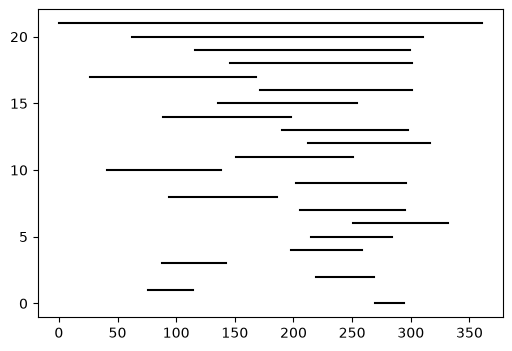

In [14]:
fig, ax = plt.subplots(figsize=(6, 4))

for i, bar in enumerate(sorted_bars):
    xs = [bar.birth, bar.death]
    ys = [i, i]
    plt.plot(xs, ys, color='black')

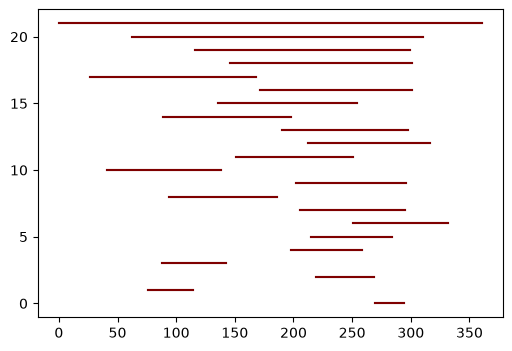

In [15]:
import tmd
cell = tmd.io.load_neuron_from_morphio(PATH_TO_SWC)
ph_apical = tmd.methods.get_ph_neuron(
    cell, 
    feature='path_distances', 
    neurite_type='apical_dendrite'
)
sorted_ph_apical = tmd.analysis.sort_ph(ph_apical)

fig, ax = plt.subplots(figsize=(6, 4))
for i, bar in enumerate(sorted_bars):
    xs = [bar.birth, bar.death]
    ys = [i, i]
    plt.plot(xs, ys, color='black')
for j in range(len(sorted_ph_apical)):
    xs = [sorted_ph_apical[j][0], sorted_ph_apical[j][1]]
    ys = [j, j]
    plt.plot(xs, ys, color='red', alpha=0.5)